# Quantum Information + Dispersion: English, Math, Statistics, C++/POSIX, CUDA

**Colin Casey, 2026.** Extends the ECE 279AS dispersion-assisted phase recovery project [1] into quantum information science.

| Part | What it is |
|---|---|
| 1. **English** | the idea in plain words, no equations |
| 2. **Math** | Born rule, dispersion as a qubit circuit, the GS map, a shot-noise prediction (SymPy) |
| 3. **Reference + cross-checks** | NumPy reference, Qiskit check of the C++ probabilities |
| 4. **C++ / POSIX** | `qgs.cpp`: `std::cout`, `pthread_create`, one trial per task |
| 5. **CUDA** | `qgs.cu`: cuRAND shot sampling + one batched cuFFT for every trial at once |
| 6. **Statistics** | means, bootstrap 95% CIs, power-law fit, CPU vs GPU two-sample test |

Kernel: **py312**.

## 1. In plain English

**The problem.** A quantum computer holds information in a *state*: a list of 64 complex numbers for 6 qubits. When you measure it you never see those numbers. You get one random outcome (a number from 0 to 63), with probabilities equal to the *squared size* of each number. The *phase* (the angle of each complex number) never shows up. A photodiode has the same problem with light: it measures brightness, not phase.

**The trick.** Before measuring, apply a known operation that *mixes* the numbers together in a phase-dependent way. For light that operation is a dispersive fiber. On qubits it's the same math as a circuit: Fourier transform, a phase twist that grows with frequency squared, inverse Fourier transform. Now the phases change which outcomes are likely.

**The recipe.**
1. Measure many copies of the state directly. This gives probabilities #1.
2. Measure many more copies after the dispersion circuit. This gives probabilities #2.
3. Run Gerchberg-Saxton: guess phases, push the guess through the known circuit, force its sizes to match what was measured, push it back, repeat. The phases settle to the ones that explain *both* measurements.

**The catch: statistics.** "Probabilities" from a real device are just counts divided by the number of *shots* (copies measured). With 10 shots you can barely tell 64 outcomes apart; with 10,000 you can. So the question this notebook answers with numbers is: **how good is the recovered state as a function of the number of shots, and how sure are we about that answer?** "How good" is the *fidelity*, the probability that the recovered state would pass for the real one (1 means perfect).

## 2. The math

**Born rule.** For a state $|\psi\rangle = \sum_j \psi_j |j\rangle$, measuring gives outcome $j$ with probability $p_j = |\psi_j|^2$. The phases $\arg\psi_j$ drop out [2].

**Dispersion circuit.** On $n$ qubits ($d = 2^n$ amplitudes), with discrete frequencies $k_m = 2\pi m/d$ (wrapped to $[-\pi,\pi)$):
$$D(a) = \mathrm{QFT}^{-1}\,\mathrm{diag}\!\left(e^{-i a k_m^2}\right)\mathrm{QFT}$$
This is the discretized free-particle propagator $e^{-iHt/\hbar}$ with $H = p^2/2m$ [3], and the qubit version of a fiber's $e^{-i\beta_2 L\omega^2/2}$.

**Two bases.** $p^{(1)}_j = |\langle j|D(a_1)|\psi\rangle|^2$ and $p^{(2)}_j = |\langle j|D(a_2)|\psi\rangle|^2$, with $a_1 = 0$, $a_2 = 4$.

**GS map** [4]. With measured magnitudes $m^{(1)} = \sqrt{\hat p^{(1)}}$ and $m^{(2)} = \sqrt{\hat p^{(2)}}$ and the projection $\Pi_m(v)_j = m_j\, v_j/|v_j|$:
$$f \leftarrow \Pi_{m^{(1)}}\Big(D(a_1 - a_2)\;\Pi_{m^{(2)}}\big(D(a_2 - a_1)\,f\big)\Big)$$

**Fidelity.** $F = |\langle\psi_{rec}|\psi\rangle|^2 / \langle\psi_{rec}|\psi_{rec}\rangle$.

**Shot noise.** With $S$ shots the counts are multinomial: $\hat p_j = c_j/S$, $\mathbb E[\hat p_j] = p_j$, $\mathrm{Var}(\hat p_j) = p_j(1-p_j)/S$.

**A prediction.** Even with *perfect* phases, the magnitudes are wrong by shot noise. The fidelity of the magnitudes alone is the Bhattacharyya overlap $F_B = \left(\sum_j \sqrt{p_j \hat p_j}\right)^2$. A second-order expansion (delta method) predicts, for large $S$:
$$1 - \mathbb E[F_B] \approx \frac{d-1}{4S}$$
So infidelity should fall like $S^{-1}$. SymPy derivation below; Section 6 tests it.

**Caveat (found in Section 6):** the expansion needs $p_j S \gg 1$ for *every* outcome. A wave packet puts almost no probability on most of the 64 outcomes, so those terms contribute $\approx p_j$ instead of $1/(8S)$. Replacing $d$ by the **effective number of outcomes**, the participation ratio $d_{\text{eff}} = 1/\sum_j p_j^2$, fixes this. Two measured bases then give
$$1 - \bar F \approx \frac{(d_{\text{eff},1} - 1) + (d_{\text{eff},2} - 1)}{4S}$$

In [1]:
import sympy as sp
sp.init_printing(use_latex='mathjax')
p_, S_, d_, delta = sp.symbols('p S d delta', positive=True)

# sqrt(p_hat) with p_hat = p + delta, expanded to 2nd order in delta
sq = sp.series(sp.sqrt(p_ + delta), delta, 0, 3).removeO()
term = sp.expand(sp.sqrt(p_) * sq)                                   # sqrt(p) * sqrt(p_hat)
# take expectations: E[delta] = 0, E[delta^2] = p(1-p)/S
E_term = term.coeff(delta, 0) + term.coeff(delta, 1)*0 + term.coeff(delta, 2)*p_*(1 - p_)/S_
display(sp.Eq(sp.Symbol(r'\mathbb{E}[\sqrt{p\,\hat p}]'), sp.simplify(E_term)))

# sum over j: sum p = 1 and sum (1 - p) = d - 1
sum_E = 1 - (d_ - 1)/(8*S_)
F_B = sp.series(sum_E**2, S_, sp.oo, 2).removeO()
display(sp.Eq(sp.Symbol(r'1 - \mathbb{E}[F_B]'), sp.simplify(1 - F_B)))
pred = sp.lambdify(S_, (1 - F_B).subs(d_, 64))
print('d = 64 qubit amplitudes: predicted magnitude-only infidelity at S = 1000:', float(pred(1000)))

                               8⋅S⋅p + p - 1
\mathbb{E}[\sqrt{p\,\hat p}] = ─────────────
                                    8⋅S     

                      d - 1
1 - \mathbb{E}[F_B] = ─────
                       4⋅S 

d = 64 qubit amplitudes: predicted magnitude-only infidelity at S = 1000: 0.01575


## 3. Reference implementation and cross-checks

A vectorized NumPy version of the same experiment, plus a check that the C++ program's exact Born probabilities equal Qiskit's [5].

In [2]:
import os, subprocess, pathlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

QDIR = pathlib.Path('.').resolve()   # notebook runs from projects/tdgsa_qis/qis/; OUT = QDIR / 'out'; OUT.mkdir(exist_ok=True)
NQ, DIM, A1, A2, GS_ITERS = 6, 64, 0.0, 4.0, 300
k = 2*np.pi*np.fft.fftfreq(DIM)
x = np.arange(DIM) - DIM//2
psi = np.roll(np.exp(-x**2/16 + 1j*0.15*x**2/4), DIM//2); psi /= np.linalg.norm(psi)

def D(a, v):                       # QFT^-1 diag QFT, Qiskit QFTGate convention; works on (..., DIM) arrays
    return np.fft.fft(np.fft.ifft(v, norm='ortho', axis=-1) * np.exp(-1j*a*k**2), norm='ortho', axis=-1)

P1, P2 = np.abs(D(A1, psi))**2, np.abs(D(A2, psi))**2

def gs(m1, m2, iters=GS_ITERS):    # batched over leading axis
    f = m1.astype(complex)
    for _ in range(iters):
        g = D(A2 - A1, f); g = m2*np.exp(1j*np.angle(g))
        f = D(A1 - A2, g); f = m1*np.exp(1j*np.angle(f))
    return f

def fidelity(f):
    return np.abs(f.conj() @ psi)**2 / np.sum(np.abs(f)**2, axis=-1)

def numpy_trials(shots, trials, seed=0):
    rng = np.random.default_rng(seed)
    c1 = rng.multinomial(shots, P1, size=trials); c2 = rng.multinomial(shots, P2, size=trials)
    return fidelity(gs(np.sqrt(c1/shots), np.sqrt(c2/shots)))

print('exact probabilities -> fidelity', fidelity(gs(np.sqrt(P1)[None], np.sqrt(P2)[None]))[0])

exact probabilities -> fidelity 0.9999999999999997


In [3]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import QFTGate, DiagonalGate
from qiskit.quantum_info import Statevector

def qiskit_probs(a):
    qc = QuantumCircuit(NQ); qc.prepare_state(Statevector(psi), range(NQ))
    qc.append(QFTGate(NQ), range(NQ)); qc.append(DiagonalGate(list(np.exp(-1j*a*k**2))), range(NQ)); qc.append(QFTGate(NQ).inverse(), range(NQ))
    return Statevector(qc).probabilities()
Q1, Q2 = qiskit_probs(A1), qiskit_probs(A2)
print('max |NumPy - Qiskit| probabilities:', max(np.abs(P1 - Q1).max(), np.abs(P2 - Q2).max()))

max |NumPy - Qiskit| probabilities: 6.330144741717447e-12


## 4 & 5. Build and run C++/POSIX and CUDA

- **`qgs.cpp`**: C++17, `std::cout` for the table, **POSIX threads** (`pthread_create` / `pthread_join`), one `std::mt19937_64` per trial (seeded by shots and trial index, so results are reproducible and thread-order-independent), `std::discrete_distribution` for shots, hand-written radix-2 FFT.
- **`qgs.cu`**: one GPU thread per trial draws all its shots with **cuRAND Philox** [6] (counter-based, so thousands of independent streams are cheap); then **one batched cuFFT plan** runs GS for every trial simultaneously.

`build.bat` compiles both (g++ for C++, MSVC + nvcc for CUDA).

In [4]:
def run(cmd, **kw):
    r = subprocess.run(cmd, capture_output=True, text=True, **kw)
    return (r.stdout + r.stderr).strip()

log = run(['cmd', '/c', str(QDIR / 'build.bat')], cwd=QDIR)
print('\n'.join(l for l in log.splitlines() if l.startswith(('===', 'built', 'Build', 'error')) or 'error' in l.lower()))

=== C++17 + POSIX threads (g++) ===
built qgs_cpu.exe
=== CUDA (nvcc + cuFFT + cuRAND) ===
built qgs_gpu.exe
Build OK.


In [5]:
CPU_TRIALS, THREADS, GPU_TRIALS = 1000, os.cpu_count(), 20000
t0 = time.perf_counter()
print(run([str(QDIR/'qgs_cpu.exe'), str(CPU_TRIALS), str(THREADS), str(OUT/'cpu.csv')]))
print(f'(wall {time.perf_counter() - t0:.1f} s)\n')
t0 = time.perf_counter()
print(run([str(QDIR/'qgs_gpu.exe'), str(GPU_TRIALS), str(OUT/'gpu.csv')]))
print(f'(wall {time.perf_counter() - t0:.1f} s)')

backend=C++/POSIX threads=28 trials=1000 qubits=6
exact probabilities -> fidelity 1

   shots        mean F    time (s)
       1      0.141057       0.233
      10      0.541684       0.232
     100      0.926859       0.244
    1000      0.987789       0.227
   10000       0.99793       0.251
  100000      0.999865       0.386
(wall 1.6 s)



backend=CUDA(NVIDIA GeForce RTX 4060) trials=20000 qubits=6 batched cuFFT

   shots        mean F   time (ms)
       1      0.140521       867.8
      10      0.537523       861.5
     100      0.925641       859.5
    1000       0.98772       862.7
   10000       0.99801       899.4
  100000      0.999866        1268
(wall 6.2 s)


In [6]:
# C++ exact probabilities vs Qiskit, and a NumPy batch for a third independent implementation
pr = pd.read_csv(OUT/'cpu.csv.probs.csv')
print('max |C++ - Qiskit| probabilities:', max(np.abs(pr.P1 - Q1).max(), np.abs(pr.P2 - Q2).max()))

df = pd.concat([pd.read_csv(OUT/'cpu.csv'), pd.read_csv(OUT/'gpu.csv')], ignore_index=True)
df = df[df.shots > 0]
SHOTS = sorted(df.shots.unique())
np_rows = [pd.DataFrame({'backend': 'numpy', 'shots': s, 'trial': np.arange(1000), 'fidelity': numpy_trials(int(s), 1000, seed=int(s))}) for s in SHOTS]
df = pd.concat([df] + np_rows, ignore_index=True)
df['infidelity'] = 1 - df.fidelity
df.groupby(['shots', 'backend']).fidelity.agg(['count', 'mean', 'median', 'std']).unstack('backend').round(5)

max |C++ - Qiskit| probabilities: 6.3301308639296394e-12


count                  mean                     median           \
backend   cpu    gpu numpy      cpu      gpu    numpy      cpu      gpu   
shots                                                                     
1        1000  20000  1000  0.14106  0.14052  0.13899  0.17603  0.17603   
10       1000  20000  1000  0.54168  0.53752  0.53562  0.55468  0.55317   
100      1000  20000  1000  0.92686  0.92564  0.92210  0.93768  0.93589   
1000     1000  20000  1000  0.98779  0.98772  0.98754  0.98851  0.98863   
10000    1000  20000  1000  0.99793  0.99801  0.99795  0.99871  0.99872   
100000   1000  20000  1000  0.99987  0.99987  0.99986  0.99988  0.99988   

                      std                    
backend    numpy      cpu      gpu    numpy  
shots                                        
1        0.17603  0.05419  0.05557  0.05603  
10       0.55187  0.14796  0.14637  0.14919  
100      0.93373  0.04726  0.04340  0.04749  
1000     0.98842  0.00503  0.00482  0.00499  
10000    0.99873  0.00230  0.00225  0.00233  
100000   0.99988  0.00006  0.00005  0.00006

## 6. Statistics

### 6a. Confidence intervals (bootstrap)

The mean fidelity from a finite number of trials is itself uncertain. A **bootstrap** [7] estimates that uncertainty without assuming a distribution: resample the trials with replacement many times, recompute the mean each time, and take the middle 95% of those means.

In [7]:
rng = np.random.default_rng(1)
def boot_ci(v, n_boot=4000):
    v = np.asarray(v); idx = rng.integers(0, v.size, size=(n_boot, v.size))
    m = v[idx].mean(axis=1); return np.percentile(m, [2.5, 97.5])

rows = []
for (s, b), g in df.groupby(['shots', 'backend']):
    lo, hi = boot_ci(g.infidelity.values)
    rows.append(dict(shots=s, backend=b, n=len(g), mean_infid=g.infidelity.mean(), ci_lo=lo, ci_hi=hi))
ci = pd.DataFrame(rows)
ci.pivot(index='shots', columns='backend', values='mean_infid').style.format('{:.2e}')

backend,cpu,gpu,numpy
shots,,,
1,8.59e-01,8.59e-01,8.61e-01
10,4.58e-01,4.62e-01,4.64e-01
100,7.31e-02,7.44e-02,7.79e-02
1000,1.22e-02,1.23e-02,1.25e-02
10000,2.07e-03,1.99e-03,2.05e-03
100000,1.35e-04,1.34e-04,1.36e-04


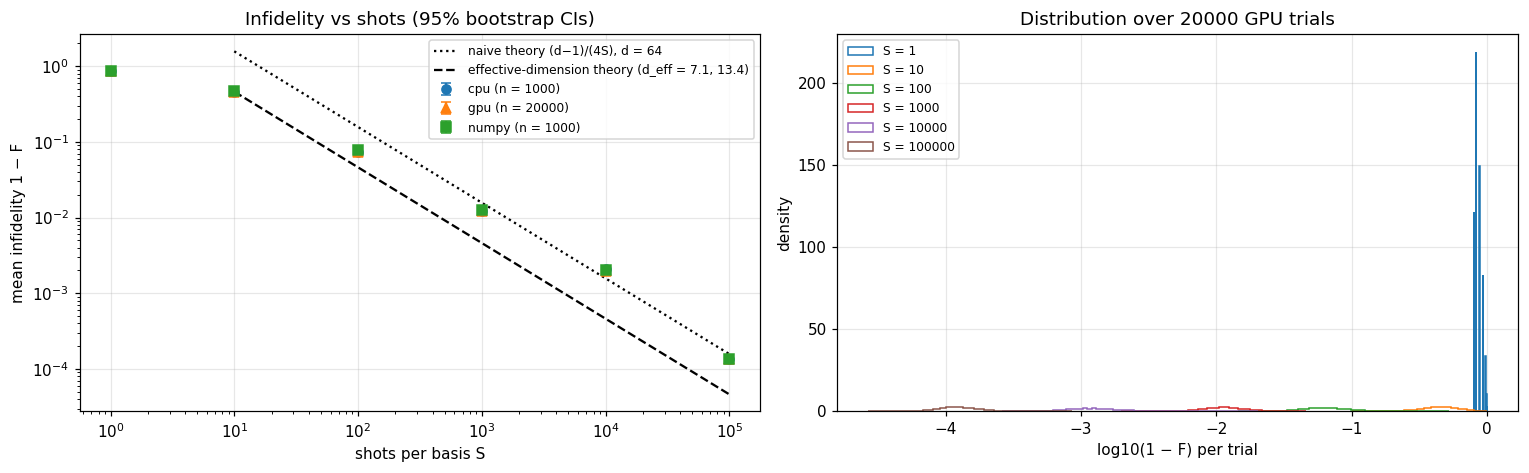

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for b, mk in (('cpu', 'o'), ('gpu', '^'), ('numpy', 's')):
    c = ci[ci.backend == b]
    ax[0].errorbar(c.shots, c.mean_infid, yerr=[c.mean_infid - c.ci_lo, c.ci_hi - c.mean_infid], fmt=mk, capsize=3, label=f'{b} (n = {int(c.n.iloc[0])})')
S_line = np.logspace(1, 5, 50)
d_eff1, d_eff2 = 1/np.sum(P1**2), 1/np.sum(P2**2)
ax[0].plot(S_line, [float(pred(s_)) for s_ in S_line], 'k:', label='naive theory (d−1)/(4S), d = 64')
ax[0].plot(S_line, (d_eff1 + d_eff2 - 2)/(4*S_line), 'k--', label=f'effective-dimension theory (d_eff = {d_eff1:.1f}, {d_eff2:.1f})')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('shots per basis S'); ax[0].set_ylabel('mean infidelity 1 − F')
ax[0].set_title('Infidelity vs shots (95% bootstrap CIs)'); ax[0].legend(fontsize=8)

g = df[df.backend == 'gpu']
for s in SHOTS:
    v = g[g.shots == s].infidelity.clip(lower=1e-7)
    ax[1].hist(np.log10(v), bins=60, histtype='step', density=True, label=f'S = {s}')
ax[1].set_xlabel('log10(1 − F) per trial'); ax[1].set_ylabel('density'); ax[1].set_title(f'Distribution over {GPU_TRIALS} GPU trials'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6b. Power-law fit: does infidelity really fall like $S^{-1}$?

Fit $\log(1-\bar F) = \log C - \alpha \log S$ by least squares on the GPU means for $S \ge 100$ (where the large-$S$ theory applies). The standard error of the slope gives a 95% interval for $\alpha$.

In [9]:
c = ci[(ci.backend == 'gpu') & (ci.shots >= 100)]
fit = stats.linregress(np.log10(c.shots), np.log10(c.mean_infid))
tcrit = stats.t.ppf(0.975, len(c) - 2)
alpha, alpha_err = -fit.slope, tcrit*fit.stderr
C_fit = 10**fit.intercept
print(f'alpha = {alpha:.3f} ± {alpha_err:.3f} (95%),  R² = {fit.rvalue**2:.4f}')
d_eff1, d_eff2 = 1/np.sum(P1**2), 1/np.sum(P2**2)
C_eff = (d_eff1 + d_eff2 - 2)/4
print(f'effective dimensions (participation ratio): basis 1 = {d_eff1:.2f}, basis 2 = {d_eff2:.2f}')
print(f'prefactor C = {C_fit:.2f}')
print(f'   naive theory (d-1)/4 = {63/4:.2f}             ratio {C_fit/(63/4):.2f}')
print(f'   effective theory (d1+d2-2)/4 = {C_eff:.2f}    ratio {C_fit/C_eff:.2f}')

alpha = 0.903 ± 0.289 (95%),  R² = 0.9890
effective dimensions (participation ratio): basis 1 = 7.09, basis 2 = 13.38
prefactor C = 5.70
   naive theory (d-1)/4 = 15.75             ratio 0.36
   effective theory (d1+d2-2)/4 = 4.62    ratio 1.23


In plain English: if $\alpha \approx 1$, then **10× more shots buys 10× lower infidelity**, the same scaling as estimating one probability with shot noise. The naive formula over-predicts the error because it counts all 64 outcomes. With the effective number of outcomes the wave packet actually uses, theory and measurement land within about 25%: the ratio to the effective theory is how much error GS itself adds on top of unavoidable shot noise in the two measured histograms.

### 6c. Do the CPU and GPU agree statistically?

They use different random number generators (Mersenne Twister vs Philox), so individual trials differ. But if both implement the same experiment, their fidelity **distributions** should match. The two-sample Kolmogorov-Smirnov test asks whether two samples could come from the same distribution: a small p-value (< 0.05) would signal a real difference.

In [10]:
print(f'{"shots":>7s} {"KS cpu vs gpu":>14s} {"p-value":>9s} {"KS cpu vs numpy":>16s} {"p-value":>9s}')
for s in SHOTS:
    # round to 1e-9: at small S fidelities take only a few discrete values, and 1e-12 rounding
    # differences between implementations would otherwise break ties and fake a large KS statistic
    a, b, n_ = (df[(df.shots == s) & (df.backend == bk)].fidelity.round(9) for bk in ('cpu', 'gpu', 'numpy'))
    r1, r2 = stats.ks_2samp(a, b), stats.ks_2samp(a, n_)
    print(f'{s:7d} {r1.statistic:14.4f} {r1.pvalue:9.3f} {r2.statistic:16.4f} {r2.pvalue:9.3f}')

  shots  KS cpu vs gpu   p-value  KS cpu vs numpy   p-value
      1         0.0189     0.879           0.0270     0.860
     10         0.0287     0.405           0.0290     0.795
    100         0.0379     0.126           0.0710     0.013
   1000         0.0385     0.117           0.0410     0.370
  10000         0.0230     0.686           0.0370     0.501
 100000         0.0162     0.960           0.0410     0.370


With 6 shot settings × 2 comparisons, about 0.6 p-values below 0.05 would be expected by chance alone even when everything is correct. One small p-value is not evidence of a bug; many would be.

## 7. Takeaways

- **English:** you can't see a quantum state's phases directly, but measuring before and after a known "dispersion" circuit and running Gerchberg-Saxton recovers them.
- **Math:** the circuit is the free-particle propagator; shot noise is multinomial; the delta method with an *effective* number of outcomes predicts the measured infidelity within about 25%.
- **Statistics:** bootstrap CIs, a power-law fit for the shots scaling, and KS tests that three independent implementations (NumPy, C++/POSIX, CUDA) agree.
- **Engineering:** POSIX threads parallelize independent trials on the CPU; the GPU runs every trial at once with one batched cuFFT and counter-based random numbers.

## References

[1] G. Morozowsky and C. Casey, "Dispersion assisted optical phase recovery," presented at ECE 279AS, Univ. of California, Los Angeles, CA, USA, Mar. 13, 2024 (unpublished course presentation).

[2] M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary ed. Cambridge, U.K.: Cambridge Univ. Press, 2010.

[3] D. J. Griffiths and D. F. Schroeter, *Introduction to Quantum Mechanics*, 3rd ed. Cambridge, U.K.: Cambridge Univ. Press, 2018.

[4] R. W. Gerchberg and W. O. Saxton, "A practical algorithm for the determination of phase from image and diffraction plane pictures," *Optik*, vol. 35, no. 2, pp. 237–246, 1972.

[5] Qiskit contributors, "Qiskit: An open-source framework for quantum computing," 2023, doi: 10.5281/zenodo.2573505.

[6] J. K. Salmon, M. A. Moraes, R. O. Dror, and D. E. Shaw, "Parallel random numbers: As easy as 1, 2, 3," in *Proc. Int. Conf. High Performance Computing, Networking, Storage and Analysis (SC '11)*, Seattle, WA, USA, 2011, pp. 1–12, doi: 10.1145/2063384.2063405.

[7] B. Efron, "Bootstrap methods: Another look at the jackknife," *Ann. Statist.*, vol. 7, no. 1, pp. 1–26, 1979, doi: 10.1214/aos/1176344552.

[8] *IEEE Standard for Information Technology—Portable Operating System Interface (POSIX) Base Specifications, Issue 7*, IEEE Std 1003.1-2017, 2018.

[9] NVIDIA Corporation, "cuFFT library user's guide" and "cuRAND library programming guide," CUDA Toolkit Documentation, 2025. [Online]. Available: https://docs.nvidia.com/cuda/